# 05 · Scaling, target transform and compression

Three preprocessing questions, answered by cross-validation before any model comparison:
1. **How to scale the features?** Ridge penalties, RBF distances, PCA, PLS and a quantum circuit's rotation angles
   all treat a unit step in every feature as equally important, and the raw features differ in scale by a factor of
   over a million.
2. **Should the models predict |μ| or a transform of it** (√|μ|, log)? The target is skewed, with a long tail.
3. **How to compress 188 features to the few inputs a quantum model can take** (one per qubit), and how many?

The answers can differ between small training sets (Track B, N ≤ 1,000) and large ones (Track A, up to 99k), so each
track gets its own choice. The latent-charge network standardizes its own per-atom inputs and predicts |μ| directly,
so these choices concern the molecule-level models.

> **Reads:** `data/processed/explore_features.parquet` and the feature catalog (notebook 04) · **Writes:**
> `results/development/nb05_preprocessing.json` (read by notebooks 06–08) and the evidence behind it ·
> **Runtime:** about 1.5 hours · **Data:** CV inside the training sets (Track B) and the `dev` set (Track A); no test set

**Choice rules, fixed before any number below was computed:**
- **Track B scaling and target:** the candidate with the lowest mean 5-fold CV MAE over every paired (model,
  feature set, seed, N ≤ 1000) cell; all candidates share the cells and folds.
- **Track A scaling and target:** the candidate with the lowest mean development-set MAE over the Track A cells
  (models fit on S_(0,N) for large N, tuned inside it).
- **Track B reduction:** for each method (PCA, partial least squares, top-k by mutual information), the mean CV MAE
  of RBF kernel ridge over seeds at each k, at N = 1000. The method with the lowest minimum wins; k is the smallest
  value whose mean MAE is within one standard error (over seeds) of that method's minimum. The project fixes the
  number of inputs at 10 (`configs/explore.yaml`, `track_b.pinned_k`); the notebook still reports the rule's choice.

Every cell is safe to re-run.

**Two classical references.** Every quantum result is compared with two kinds of classical model. **Track A**
is the most accurate classical model we could build (any training size up to the full 99,198-molecule pool, all
188 features or per-atom features). **Track B** is classical models restricted to exactly what the quantum models
get (at most 1,000 training molecules, the same 10 PLS inputs, preprocessing, folds and tuning budget). Details:
[docs/methods.md, section 5](../docs/methods.md#5-two-classical-references).

In [1]:
# Environment check: stops here, with setup instructions, unless this kernel is the project
# environment (README.md, "Setup"). Version differences from requirements.txt only warn.
try:
    from qm9dipole.provenance import check_environment
except ModuleNotFoundError as e:
    raise RuntimeError(
        "The qm9dipole package is not installed in this kernel's environment. Follow "
        "README.md (Setup), then select that environment as the notebook kernel."
    ) from e

print(check_environment())

environment OK: Python 3.12.14, 16 pinned packages checked, 0 differ; package and notebook are in the same checkout


In [2]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.pipeline import Pipeline

from qm9dipole import REPO_ROOT
from qm9dipole.analysis import summarize_curves
from qm9dipole.evaluate import dev_curve, learning_curve
from qm9dipole.explore import PREPROCESSING_PATH, feature_sets, load_catalog, load_config, load_features
from qm9dipole.models import classical
from qm9dipole.models.fitters import TabularFitter, XGBFitter
from qm9dipole.plots import INK_SECONDARY, MODEL_COLORS, MODEL_LABELS, MUTED, SERIES, SURFACE, use_style
from qm9dipole.preprocess import scaling_steps
from qm9dipole.provenance import config_hash, git_hash, save_result
from qm9dipole.splits import load_splits

use_style()
FIG_DIR = REPO_ROOT / "figures"
CFG = load_config()
features = load_features()
SETS = feature_sets(load_catalog())
splits = load_splits()
y = features["mu"]
pool = features.loc[splits.pool]
TRACK_B = {s: {n: by_n[n] for n in splits.track_b_sizes} for s, by_n in splits.train.items()}
COMPARE = ("structure+", "all_legal")
DEV = {"dev": splits.dev}
print(f"{len(features):,} development-universe molecules; training pool {len(pool):,}; Track B sizes {splits.track_b_sizes}")
print("feature sets:", ", ".join(f"{s} ({len(SETS[s])})" for s in ("composition", "cm", "structure", "structure+", "all_legal")))

108,381 development-universe molecules; training pool 99,198; Track B sizes [100, 300, 1000]
feature sets: composition (5), cm (29), structure (31), structure+ (53), all_legal (188)


## 1. Why scaling matters here

Ridge's penalty, the RBF kernel's distances, PCA, partial least squares and the quantum feature map's rotation
angles all treat a unit step in every feature as equally important. Raw features differ in scale by orders of
magnitude, so without scaling the largest-variance features would dominate all of them. Trees (XGBoost) split on
one feature at a time and are unaffected by monotone rescaling.

In [3]:
spread = pool[SETS["all_legal"]].std()
print(f"standard deviation across the {len(spread)} all_legal features: {spread.min():.3g} to {spread.max():.3g} "
      f"(ratio {spread.max() / spread[spread > 0].min():,.0f})")
display(spread.sort_values(ascending=False).iloc[[0, 1, 2, -3, -2, -1]].rename("std").to_frame()
        .style.format("{:.3g}").set_caption("largest and smallest spreads"))

standard deviation across the 188 all_legal features: 0.000105 to 147 (ratio 1,396,789)

,std
inertia_moment_2,147
inertia_moment_3,145
inertia_moment_1,46.9
rdf_NF_0.90,0.000237
rdf_OF_0.90,0.000147
rdf_HF_0.90,0.000105


## 2. What each scaling does to the shape

Five candidates (`src/qm9dipole/preprocess.py`): z-score (**standard**), median/IQR (**robust**), log of the skewed
columns then z-score (**log_standard**), a fitted power transform (**yeo_johnson**), and a rank map to a normal
(**quantile_normal**). Fit on the pool for description only (models refit inside every fold). The share of values
beyond ±3 matters for the quantum feature map: angles wrap every 2π, so far-out values alias onto ordinary ones.

,median |skew|,max |skew|,max |value|,share beyond ±3
scaling,,,,
standard,1.45,58.5,10.0,1.05%
robust,1.40,218.7,10.0,1.40%
log_standard,1.03,58.5,10.0,0.92%
yeo_johnson,0.52,58.5,10.0,0.57%
quantile_normal,1.04,58.6,5.2,46.65%


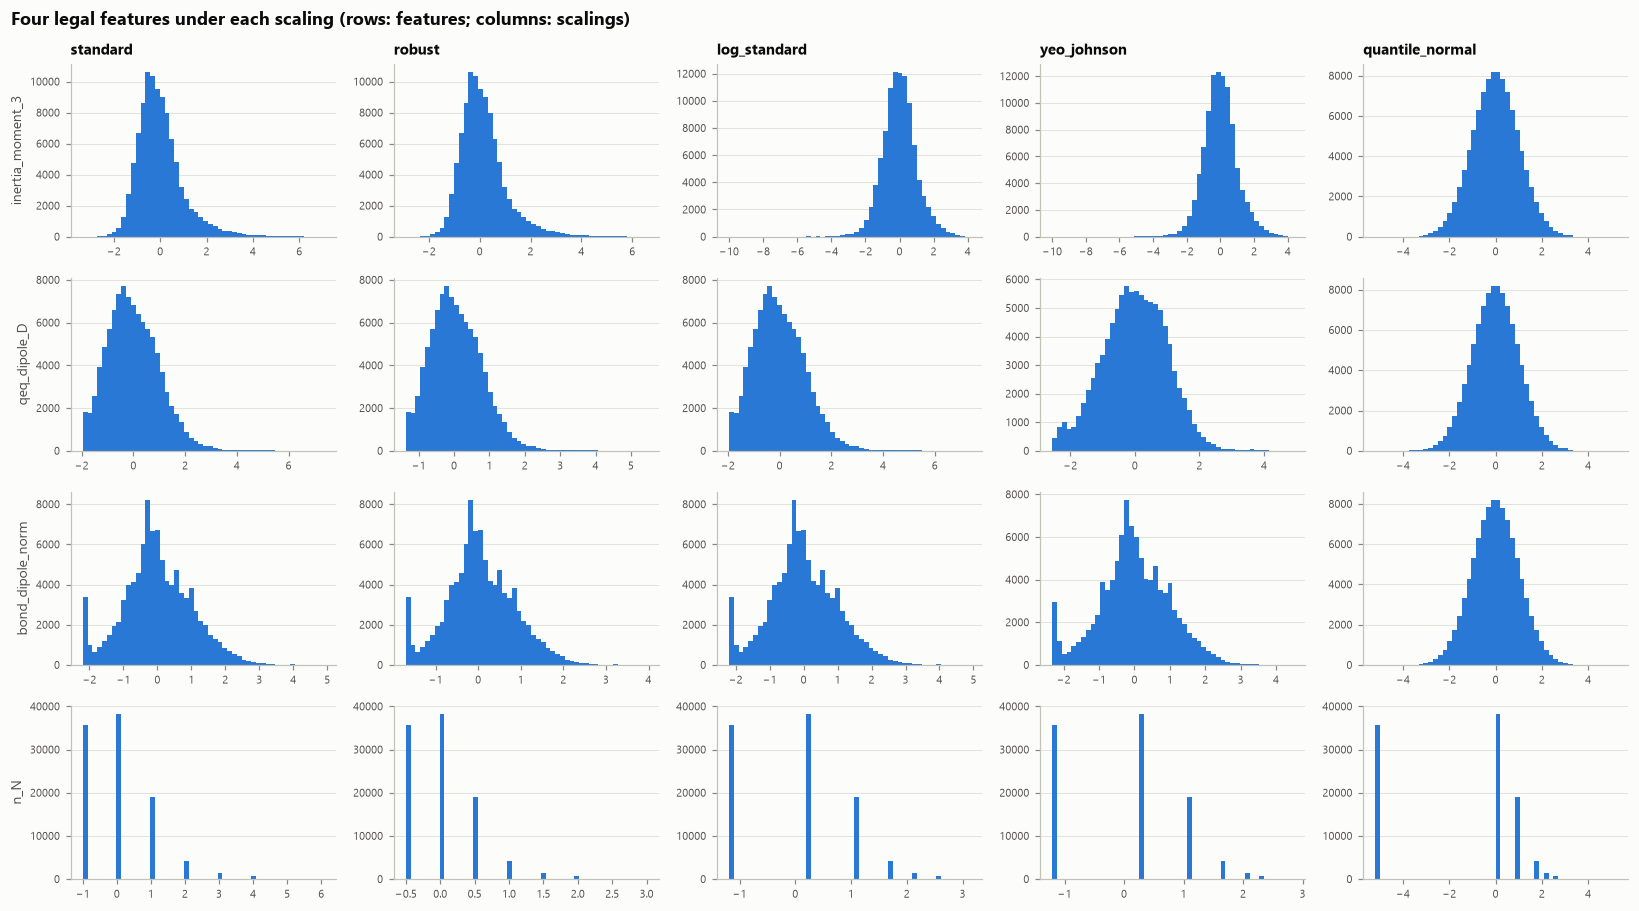

In [4]:
from qm9dipole.provenance import figure_file, results_file
CANDIDATES = CFG["standardization"]["candidates"]
SIGMA = CFG["quantum"]["angle_sigma"]
legal_X = pool[SETS["all_legal"]].to_numpy()
shape_rows, scaled_pool = [], {}
for sc in CANDIDATES:
    Z = Pipeline(scaling_steps(sc, CFG["standardization"]["skew_threshold"])).fit_transform(legal_X)
    scaled_pool[sc] = Z
    sk = pd.DataFrame(Z).skew().abs()
    shape_rows.append({"scaling": sc, "median |skew|": sk.median(), "max |skew|": sk.max(),
                       "max |value|": np.abs(Z).max(), f"share beyond ±{SIGMA}": (np.abs(Z) > SIGMA).mean()})
shape = pd.DataFrame(shape_rows).set_index("scaling")
display(shape.style.format({"median |skew|": "{:.2f}", "max |skew|": "{:.1f}", "max |value|": "{:.1f}",
                            f"share beyond ±{SIGMA}": "{:.2%}"}))

show = ["inertia_moment_3", "qeq_dipole_D", "bond_dipole_norm", "n_N"]
idx = [SETS["all_legal"].index(c) for c in show]
fig, axes = plt.subplots(len(show), len(CANDIDATES), figsize=(15, 8.4))
for i, (col, j) in enumerate(zip(show, idx)):
    for k, sc in enumerate(CANDIDATES):
        ax = axes[i, k]
        ax.hist(scaled_pool[sc][:, j], bins=50, color=SERIES[0], linewidth=0)
        ax.tick_params(labelsize=7)
        ax.grid(axis="x", visible=False)
        if i == 0:
            ax.set_title(sc, fontsize=10)
        if k == 0:
            ax.set_ylabel(col, fontsize=9)
fig.suptitle("Four legal features under each scaling (rows: features; columns: scalings)", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(figure_file("nb05_scaling_shapes.png"))
plt.show()
del scaled_pool

## 3. Choose the scaling

**Track B** (N ≤ 1000): ridge and RBF kernel ridge on structure+ and all_legal, 5-fold CV inside every S_(s,N), the
same folds for every candidate. **Track A** (large N): ridge fit on S_(0,10000) and on the full pool, and RBF kernel
ridge on S_(0,3000), each tuned on an inner validation split of its training set, scored on the development set.
Targets are standardized here; the target transform is chosen next.

In [5]:
start = time.perf_counter()
frames = {name: features[SETS[name]] for name in COMPARE}
runs = []
for sc in CANDIDATES:
    def make_specs(seed, fname, sc=sc):
        return {m: classical.build(m, seed, scaling=sc, n_features=len(SETS[fname])) for m in ("ridge", "rbf_krr")}
    res, _ = learning_curve(make_specs, frames, y, TRACK_B, progress=False)
    runs.append(res.assign(scaling=sc))
    print(f"Track B {sc:16s} done ({(time.perf_counter() - start) / 60:.1f} min)", flush=True)
scaling_b = pd.concat(runs, ignore_index=True)

FULL = len(splits.pool)
A_CELLS = {("ridge", 10000), ("ridge", FULL), ("rbf_krr", 3000)}
runs = []
for sc in CANDIDATES:
    def make_fitters(seed, n, sc=sc):
        out = {}
        for fname in COMPARE:
            for m in ("ridge", "rbf_krr"):
                if (m, n) in A_CELLS:
                    est, grid = classical.build(m, seed, scaling=sc, n_features=len(SETS[fname]))
                    out[f"{m}|{fname}"] = TabularFitter(features[SETS[fname]], est, grid, seed)
        return out
    res, _ = dev_curve(make_fitters, {0: {n: splits.train[0][n] for n in (3000, 10000, FULL)}}, DEV, y, progress=False)
    runs.append(res.assign(scaling=sc))
    print(f"Track A {sc:16s} done ({(time.perf_counter() - start) / 60:.1f} min)", flush=True)
scaling_a = pd.concat(runs, ignore_index=True)
scaling_a[["model", "features"]] = scaling_a["model"].str.split("|", expand=True)

Track B standard         done (0.6 min)


Track B robust           done (1.2 min)


Track B log_standard     done (1.7 min)


Track B yeo_johnson      done (3.9 min)


Track B quantile_normal  done (4.5 min)


Track A standard         done (4.9 min)


Track A robust           done (5.4 min)


Track A log_standard     done (6.0 min)


Track A yeo_johnson      done (10.4 min)


Track A quantile_normal  done (11.1 min)


In [6]:
def choose(results, by, value="mae_D"):
    paired = results.pivot_table(index=[c for c in ("seed", "n_train", "model", "features") if c in results], columns=by, values=value)
    mean = paired.mean().loc[CANDIDATES] if by == "scaling" else paired.mean()
    return mean, paired

mean_b, paired_b = choose(scaling_b, "scaling")
mean_a, paired_a = choose(scaling_a, "scaling")
best_scaling = {"track_b": mean_b.idxmin(), "track_a": mean_a.idxmin()}
table = pd.DataFrame({"Track B: mean CV MAE (D)": mean_b, "Track B: cells won": paired_b.eq(paired_b.min(axis=1), axis=0).mean(),
                      "Track A: mean dev MAE (D)": mean_a, "Track A: cells won": paired_a.eq(paired_a.min(axis=1), axis=0).mean()})
display(table.style.format({c: "{:.4f}" if "MAE" in c else "{:.0%}" for c in table.columns})
        .set_caption(f"{len(paired_b)} Track B cells, {len(paired_a)} Track A cells"))
display(scaling_b.pivot_table(index=["n_train", "model"], columns="scaling", values="mae_D")[CANDIDATES]
        .style.format("{:.3f}").highlight_min(axis=1, props="font-weight: bold").set_caption("Track B: mean CV MAE (D) by N and model"))
display(scaling_a.pivot_table(index=["model", "n_train", "features"], columns="scaling", values="mae_D")[CANDIDATES]
        .style.format("{:.3f}").highlight_min(axis=1, props="font-weight: bold").set_caption("Track A: development-set MAE (D)"))
print("chosen scaling:", best_scaling)

,Track B: mean CV MAE (D),Track B: cells won,Track A: mean dev MAE (D),Track A: cells won
scaling,,,,
log_standard,0.5802,25%,0.4438,100%
quantile_normal,0.6198,3%,0.4611,0%
robust,0.6146,3%,0.4638,0%
standard,0.5863,11%,0.4516,0%
yeo_johnson,0.5768,58%,0.4560,0%


chosen scaling: {'track_b': 'yeo_johnson', 'track_a': 'log_standard'}


## 4. Choose the target transform

A model fit on a transformed target is inverted back to debye before scoring, so only accuracy in debye counts.
Every candidate also standardizes, so kernel ridge's missing intercept never biases it toward 0 D. Track B: ridge,
RBF kernel ridge and XGBoost (a small fixed grid) by 5-fold CV; Track A: ridge on S_(0,10000) and the full pool, kernel ridge
on S_(0,3000) and XGBoost (randomized search, 8 draws) on S_(0,10000), scored on the development set. Scaling as
chosen above, per track.

In [7]:
TARGETS = CFG["standardization"]["target_candidates"]
start = time.perf_counter()
runs = []
for tg in TARGETS:
    def make_specs(seed, fname, tg=tg):
        return {m: classical.build(m, seed, scaling=best_scaling["track_b"], target=tg, n_features=len(SETS[fname]))
                for m in ("ridge", "rbf_krr", "xgb")}
    res, _ = learning_curve(make_specs, frames, y, TRACK_B, progress=False)
    runs.append(res.assign(target=tg))
    print(f"Track B {tg:9s} done ({(time.perf_counter() - start) / 60:.1f} min)", flush=True)
target_b = pd.concat(runs, ignore_index=True)

A_CELLS_T = {("ridge", 10000), ("ridge", FULL), ("rbf_krr", 3000), ("xgb", 10000)}
runs = []
for tg in TARGETS:
    def make_fitters(seed, n, tg=tg):
        out = {}
        for fname in COMPARE:
            for m in ("ridge", "rbf_krr", "xgb"):
                if (m, n) not in A_CELLS_T:
                    continue
                if m == "xgb":
                    out[f"{m}|{fname}"] = XGBFitter(features[SETS[fname]], seed, n_iter=8, target=tg)
                else:
                    est, grid = classical.build(m, seed, scaling=best_scaling["track_a"], target=tg, n_features=len(SETS[fname]))
                    out[f"{m}|{fname}"] = TabularFitter(features[SETS[fname]], est, grid, seed)
        return out
    res, _ = dev_curve(make_fitters, {0: {n: splits.train[0][n] for n in (3000, 10000, FULL)}}, DEV, y, progress=False)
    runs.append(res.assign(target=tg))
    print(f"Track A {tg:9s} done ({(time.perf_counter() - start) / 60:.1f} min)", flush=True)
target_a = pd.concat(runs, ignore_index=True)
target_a[["model", "features"]] = target_a["model"].str.split("|", expand=True)

tb = target_b.groupby("target")[["mae_D", "rmse_D"]].mean().loc[TARGETS]
ta = target_a.groupby("target")[["mae_D", "rmse_D"]].mean().loc[TARGETS]
best_target = {"track_b": tb["mae_D"].idxmin(), "track_a": ta["mae_D"].idxmin()}
display(pd.concat({"Track B (CV)": tb, "Track A (dev)": ta}, axis=1).style.format("{:.4f}")
        .set_caption("mean MAE and RMSE (D) by target transform"))
display(target_b.pivot_table(index=["n_train", "model"], columns="target", values="mae_D")[TARGETS]
        .style.format("{:.3f}").highlight_min(axis=1, props="font-weight: bold").set_caption("Track B: mean CV MAE (D)"))
display(target_a.pivot_table(index=["model", "n_train", "features"], columns="target", values="mae_D")[TARGETS]
        .style.format("{:.3f}").highlight_min(axis=1, props="font-weight: bold").set_caption("Track A: development-set MAE (D)"))
print("chosen target transform:", best_target)

Track B standard  done (8.1 min)


Track B sqrt      done (16.3 min)


Track B log1p     done (24.7 min)


Track A standard  done (32.8 min)


Track A sqrt      done (43.4 min)


Track A log1p     done (52.2 min)


chosen target transform: {'track_b': 'sqrt', 'track_a': 'standard'}


## 5. Track B: how many inputs, and which?

The quantum model takes one input per qubit, so the matched classical model must too. Three ways to reduce the 188
all_legal features to k inputs, each fit inside the pipeline on every fold and followed by re-standardization (the
same numbers an angle encoding would see):
- **PCA:** the k directions of largest variance (unsupervised). the components that track |μ| need not be the
  largest;
- **PLS** (partial least squares): the k directions of largest covariance with the target (supervised);
- **top-k by mutual information** with the target (supervised; keeps original, interpretable features).

RBF kernel ridge (the classical twin of a quantum kernel model) by 5-fold CV inside every S_(s,N), N ≤ 1000, for
k from 2 to 32; the uncompressed model is the reference.

252 tuned CV runs in 39.6 min


,min_mae,k_at_min,k_one_se,mae_at_k_one_se
kbest,0.510,32.000000,32.000000,0.510
pca,0.574,32.000000,32.000000,0.574
pls,0.488,24.000000,8.000000,0.500


chosen reduction: pls, k = 10 (pinned in configs/explore.yaml; the one-standard-error rule gives k = 8)


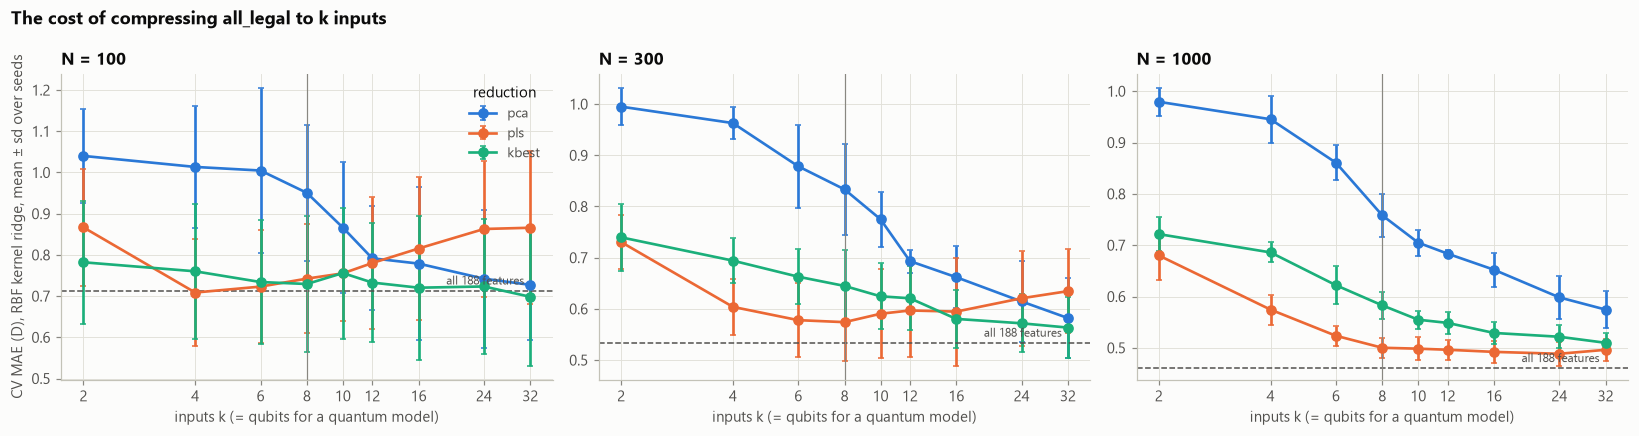

In [8]:
KS = [2, 4, 6, 8, 10, 12, 16, 24, 32]
METHODS = list(classical.REDUCTIONS)
frames_k = {f"{m}/{k}": features[SETS["all_legal"]] for m in METHODS for k in KS}
frames_k["all_legal (no reduction)"] = features[SETS["all_legal"]]

def make_specs(seed, fname):
    if "/" not in fname:
        return {"rbf_krr": classical.build("rbf_krr", seed, scaling=best_scaling["track_b"], target=best_target["track_b"],
                                           n_features=len(SETS["all_legal"]))}
    m, k = fname.split("/")
    return {"rbf_krr": classical.build("rbf_krr", seed, scaling=best_scaling["track_b"], target=best_target["track_b"],
                                       reduction=(m, int(k)))}

start = time.perf_counter()
kcurve, _ = learning_curve(make_specs, frames_k, y, TRACK_B, progress=False)
print(f"{len(kcurve)} tuned CV runs in {(time.perf_counter() - start) / 60:.1f} min")
kcurve["method"] = kcurve["features"].map(lambda f: f.split("/")[0] if "/" in f else "none")
kcurve["k"] = kcurve["features"].map(lambda f: int(f.split("/")[1]) if "/" in f else len(SETS["all_legal"]))
ks = kcurve.groupby(["n_train", "method", "k"])["mae_D"].agg(["mean", "std", "count"]).reset_index()
ks["se"] = ks["std"] / np.sqrt(ks["count"])

N_CHOICE = max(splits.track_b_sizes)
at = ks[(ks["n_train"] == N_CHOICE) & (ks["method"] != "none")]
choice = {}
for m, g in at.groupby("method"):
    best = g.loc[g["mean"].idxmin()]
    k_star = int(g.loc[g["mean"] <= best["mean"] + best["se"], "k"].min())
    choice[m] = {"min_mae": float(best["mean"]), "k_at_min": int(best["k"]), "k_one_se": k_star,
                 "mae_at_k_one_se": float(g.loc[g["k"] == k_star, "mean"].iloc[0])}
best_method = min(choice, key=lambda m: choice[m]["min_mae"])
reduction = {"method": best_method, "k": choice[best_method]["k_one_se"], "chosen_at_n": N_CHOICE, "per_method": choice}
PINNED_K = CFG["track_b"].get("pinned_k")  # configs/explore.yaml: the k every later step uses
if PINNED_K is not None:
    reduction.update(k_rule=reduction["k"], k=int(PINNED_K))
display(pd.DataFrame(choice).T.style.format({"min_mae": "{:.3f}", "mae_at_k_one_se": "{:.3f}"})
        .set_caption(f"N = {N_CHOICE}: per method, the best k and the smallest k within one standard error"))
print(f"chosen reduction: {best_method}, k = {reduction['k']}"
      + (f" (pinned in configs/explore.yaml; the one-standard-error rule gives k = {reduction['k_rule']})" if PINNED_K else ""))

fig, axes = plt.subplots(1, len(splits.track_b_sizes), figsize=(15, 4), sharey=False)
for ax, n in zip(axes, splits.track_b_sizes):
    for color, m in zip(SERIES, METHODS):
        g = ks[(ks["n_train"] == n) & (ks["method"] == m)]
        ax.errorbar(g["k"], g["mean"], yerr=g["std"], color=color, marker="o", capsize=2, label=m)
    ref = ks[(ks["n_train"] == n) & (ks["method"] == "none")]["mean"].iloc[0]
    ax.axhline(ref, color=INK_SECONDARY, linewidth=1, linestyle="--")
    ax.annotate(f"all {len(SETS['all_legal'])} features", (KS[-1], ref), xytext=(-4, 4), textcoords="offset points",
                ha="right", color=INK_SECONDARY, fontsize=8)
    ax.axvline(8, color=MUTED, linewidth=0.8)
    ax.set(xscale="log", xticks=KS, xlabel="inputs k (= qubits for a quantum model)", title=f"N = {n}")
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}")
    ax.xaxis.set_minor_locator(plt.NullLocator())
axes[0].set_ylabel("CV MAE (D), RBF kernel ridge, mean ± sd over seeds")
axes[0].legend(title="reduction")
fig.suptitle("The cost of compressing all_legal to k inputs", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(figure_file("nb05_compression_cost.png"))
plt.show()
display(ks[ks["method"] != "none"].pivot_table(index=["method", "k"], columns="n_train", values="mean")
        .style.format("{:.3f}").set_caption("mean CV MAE (D) by method, k and N"))

In [9]:
# What the chosen reduction keeps, described on S_(0,1000) (top-k features are directly interpretable).
from sklearn.feature_selection import mutual_info_regression

ids = splits.train[0][N_CHOICE]
est, _ = classical.build("ridge", 0, scaling=best_scaling["track_b"], target=best_target["track_b"],
                         reduction=("kbest", reduction["k"]))
est.fit(features.loc[ids, SETS["all_legal"]].to_numpy(), y.loc[ids].to_numpy())
picked = np.array(SETS["all_legal"])[est.regressor_.named_steps["reduce"].get_support()]
print(f"top-{reduction['k']} features by mutual information on S_(0,{N_CHOICE}): {', '.join(picked)}")

top-10 features by mutual information on S_(0,1000): heteroatom_offset, bond_polarity_total, bond_dipole_norm, en_point_dipole, atoms_C4, qeq_dipole_D, qeq_max_abs_charge, rdf_CN_0.90, rdf_CO_1.44, cm_16


### 5b. Which single features best predict |μ|?

Every candidate ranked by how much it tells us about |μ| **on its own**: mutual information (nats; any dependence,
linear or not; 0 means independent), with Spearman ρ for direction. Two lists, computed on a random 20,000
molecules of the training pool (no development or test molecule):
1. **all features, engineered and from the data:** every feature notebook 04 kept, plus the QM9 fields it does not
   hold (n_atoms, n_heavy and the rotational constants A, B, C);
2. **natural features:** the numbers QM9 gives directly for each molecule (the 14 computed properties besides μ,
   plus counts read off the atom list). There are only 21, so this list stops there.

Descriptive only: nothing downstream reads it. Two cautions. A **DFT output** cannot predict |μ| for a new molecule
(running that calculation already gives |μ|), so for prediction read the **headline-legal** rows. And a univariate
ranking misses features that only help in combination, while near-copies of one feature rank side by side.

In [10]:
# Which single features best predict |μ|? A description for the reader; nothing downstream reads it.
from qm9dipole.analysis import rank_features
from qm9dipole.data import load_qm9_table
from qm9dipole.eda import natural_features, natural_role

TOP = 32
sample = pool.sample(min(CFG["eda"]["subsample"], len(pool)), random_state=0).index  # training pool only
catalog = load_catalog()
kept = catalog[catalog["kept"] & (catalog["level"] == "molecule")].set_index("feature")
qm9 = load_qm9_table()
natural = natural_features(qm9[qm9["id"].isin(sample)]).loc[sample]

# Every kept feature notebook 02 built, plus the natural fields it does not hold at all (n_atoms,
# n_heavy, A, B, C). Fields notebook 02 dropped as redundant (U, H and G next to U0) stay out.
extra = [c for c in natural.columns if c not in set(catalog["feature"])]
combined = features.loc[sample, kept.index.tolist()].join(natural[extra])
LEGAL, DFT_ONLY = "Z and R (headline-legal)", "DFT output (exploration only)"
role = {f: LEGAL if kept.loc[f, "legal"] else DFT_ONLY for f in kept.index}
role |= {f: LEGAL if natural_role(f).startswith("function of Z and R") else DFT_ONLY for f in natural.columns}
source = {f: kept.loc[f, "block"] for f in kept.index} | {f: "QM9 field" for f in extra}
nat_source = {f: "counted from Z" if f.startswith("n_") else "QM9 field" for f in natural.columns}


def show(ranking, src, title):
    top = ranking.head(TOP)
    table = top.assign(source=top.index.map(src), role=top.index.map(role))
    display(table.style.format({"MI (nats)": "{:.3f}", "Spearman ρ": "{:+.2f}"}).set_caption(title))


ranked_all = rank_features(combined, y.loc[sample])
ranked_natural = rank_features(natural, y.loc[sample])
show(ranked_all, source, f"Top {TOP} of {len(ranked_all)} features (engineered and from the data), "
     f"by mutual information with |μ| ({len(sample):,} training-pool molecules)")
show(ranked_natural, nat_source, f"All {len(ranked_natural)} natural features (QM9 gives only {len(natural.columns)} "
     "numbers per molecule directly), by mutual information with |μ|")
legal_top = ranked_all[ranked_all.index.map(role) == LEGAL].head(TOP)
print(f"{(ranked_all.head(TOP).index.map(role) == DFT_ONLY).sum()} of the top {TOP} are DFT outputs; the best "
      f"headline-legal features: {', '.join(legal_top.index[:8])}, ...")

,rank,MI (nats),Spearman ρ,source,role
feature,,,,,
charge_dipole_D,1,1.065,+0.92,charge,DFT output (exploration only)
qeq_dipole_D,2,0.515,+0.77,qeq,Z and R (headline-legal)
bond_polarity_total,3,0.377,-0.03,engineered,Z and R (headline-legal)
bond_dipole_norm,4,0.298,+0.42,engineered,Z and R (headline-legal)
U0,5,0.267,-0.24,dft_property,DFT output (exploration only)
en_point_dipole,6,0.224,+0.54,engineered,Z and R (headline-legal)
rdf_CO_1.44,7,0.193,-0.03,rdf,Z and R (headline-legal)
lumo,8,0.177,-0.41,dft_property,DFT output (exploration only)
rdf_CN_0.90,9,0.176,+0.36,rdf,Z and R (headline-legal)


,rank,MI (nats),Spearman ρ,source,role
feature,,,,,
G,1,0.268,-0.24,QM9 field,DFT output (exploration only)
U0,2,0.267,-0.24,QM9 field,DFT output (exploration only)
H,3,0.267,-0.24,QM9 field,DFT output (exploration only)
U,4,0.267,-0.24,QM9 field,DFT output (exploration only)
lumo,5,0.177,-0.41,QM9 field,DFT output (exploration only)
zpve,6,0.166,-0.36,QM9 field,DFT output (exploration only)
n_C,7,0.142,-0.37,counted from Z,Z and R (headline-legal)
gap,8,0.133,-0.31,QM9 field,DFT output (exploration only)
n_H,9,0.127,-0.37,counted from Z,Z and R (headline-legal)


6 of the top 32 are DFT outputs; the best headline-legal features: qeq_dipole_D, bond_polarity_total, bond_dipole_norm, en_point_dipole, rdf_CO_1.44, rdf_CN_0.90, qeq_max_abs_charge, atoms_C4, ...


## 6. Effective dimension: how many independent directions do the features span?

Four measures on the scaled pool (Track A scaling): the **participation ratio** PR = (Σλ)² / Σλ² of the covariance
eigenvalues (the number of equally strong directions with the same overall spread); **components for 90 / 95 /
99 %** of the variance; and the **condition number** √(λ_max / λ_min).

In [11]:
from qm9dipole.complexity import components_for_share, condition_number, participation_ratio

dim_rows = []
for name in ("composition", "cm", "structure", "structure+", "all_legal"):
    Z = Pipeline(scaling_steps(best_scaling["track_a"], CFG["standardization"]["skew_threshold"])).fit_transform(pool[SETS[name]])
    lam = np.linalg.eigvalsh(np.cov(Z, rowvar=False))[::-1]
    dim_rows.append({"feature set": name, "features": Z.shape[1], "participation ratio": participation_ratio(lam),
                     "k for 90%": components_for_share(lam, 0.90), "k for 95%": components_for_share(lam, 0.95),
                     "k for 99%": components_for_share(lam, 0.99), "condition number": condition_number(lam)})
dims = pd.DataFrame(dim_rows).set_index("feature set")
display(dims.style.format({"participation ratio": "{:.1f}", "condition number": "{:.3g}"}))

,features,participation ratio,k for 90%,k for 95%,k for 99%,condition number
feature set,,,,,,
composition,5,3.1,4,4,5,4.65
cm,29,4.9,12,17,24,inf
structure,31,9.1,13,15,20,124
structure+,53,11.6,18,22,30,818
all_legal,188,10.9,36,53,92,inf


## 7. Save the choices for notebooks 06–08

In [12]:
choice_out = {
    "scaling": best_scaling, "target": best_target, "reduction": reduction,
    "rules": {"scaling_and_target": "lowest mean MAE over the paired cells of each track (CV for Track B, dev set for Track A)",
              "reduction": "at the largest Track B size, the method with the lowest minimum mean CV MAE (RBF kernel ridge); "
                           "k = smallest within one standard error over seeds of that minimum (k_rule); "
                           "configs/explore.yaml track_b.pinned_k, when set, fixes the k later steps use"},
    "scaling_mean_mae": {"track_b": mean_b.round(5).to_dict(), "track_a": mean_a.round(5).to_dict()},
    "target_mean_mae": {"track_b": tb["mae_D"].round(5).to_dict(), "track_a": ta["mae_D"].round(5).to_dict()},
    "kbest_features": picked.tolist(),
    "effective_dimension": dims[["features", "participation ratio", "k for 95%"]].round(2).reset_index().to_dict("records"),
    "config_hash": config_hash(CFG), "git_hash": git_hash(),
}
PREPROCESSING_PATH.write_text(json.dumps(choice_out, indent=1) + "\n")
_ = save_result(pd.concat([scaling_b.assign(track="B"), scaling_a.assign(track="A")], ignore_index=True), "nb05_scaling",
                label="exploratory; legal inputs; Track B CV inside S_(s,N); Track A dev set")
_ = save_result(pd.concat([target_b.assign(track="B"), target_a.assign(track="A")], ignore_index=True), "nb05_target",
                label="exploratory; legal inputs; Track B CV inside S_(s,N); Track A dev set")
_ = save_result(kcurve, "nb05_compression_cost", label="exploratory; legal inputs; CV inside S_(s,N), N <= 1000")
print(f"wrote {PREPROCESSING_PATH.relative_to(REPO_ROOT).as_posix()}: scaling {best_scaling}, target {best_target}, "
      f"reduction {reduction['method']} k = {reduction['k']}")

wrote results/development/nb05_preprocessing.json: scaling {'track_b': 'yeo_johnson', 'track_a': 'log_standard'}, target {'track_b': 'sqrt', 'track_a': 'standard'}, reduction pls k = 10


## What we learned

1. **Feature scales differ by a factor of 1.4 million** across the 188 all_legal features (sd 1.05 × 10⁻⁴ for
   `rdf_HF_0.90` up to 147 for a moment of inertia), so every distance- or penalty-based model needs scaling.
   Yeo-Johnson leaves the least skew (median |skew| 0.52 against 1.45 for z-scores) and the fewest values beyond ±3
   (0.57%). The quantile map is bounded (±5.2) but puts 47% of values beyond ±3, because zero-inflated counts land on
   its tails: a poor input for an angle encoding.
2. **Track B scaling (N ≤ 1000): Yeo-Johnson**, best in 21 of the 36 paired CV cells (mean CV MAE 0.577 D, against
   0.580 for log_standard and 0.586 for z-scores). Every unbounded scaling clips scaled values at ±10
   (`preprocess.ClipScaled`). Without that clip, ridge blew up in 3 of the 36 cells for each z-score scaling (CV MAE up
   to ~10⁴ D): radial-distribution bins at physically empty distances (`rdf_OF_0.90`, `rdf_NF_0.90`: an O–F pair
   0.9 Å apart never occurs) have 1–3 non-zero training values, so their spread is ~10⁻¹² and a new molecule's tiny
   value becomes a z-score of 10⁷.
3. **Track A scaling (large N): log_standard**, best in all 6 development-set cells (mean dev MAE 0.444 D, against
   0.452 for z-scores): for example ridge on all_legal at the full pool 0.446 D and RBF kernel ridge on S_(0,3000)
   0.386 D.
4. **Target transform: √|μ| for Track B, standardized |μ| for Track A**, by mean MAE with small margins (Track B
   0.5745 vs 0.5760 D; Track A 0.4202 vs 0.4211 D); log1p is worst in both tracks. Paired cell by cell, √|μ| wins for
   ridge (median −0.014 D) and kernel ridge (−0.005 D) and loses for XGBoost (+0.005 D), so it suits the kernel models
   the quantum comparison uses.
5. **Track B reduction: partial least squares, with 10 inputs.** At N = 1000 RBF kernel ridge reaches CV MAE 0.498 D on
   10 PLS components (minimum 0.488 D at k = 24), against 0.555 D on the top-10 features by mutual information and
   0.705 D on 10 principal components. PCA needs 32 components to reach 0.574 D: it ranks variance, not relevance to
   |μ|. At N = 100, fewer PLS components do better (0.709 D at k = 4 vs 0.755 D at k = 10), because supervised
   directions fit on 80 molecules are noisy.
6. **Why 10 and not 8.** The one-standard-error rule picks the smallest k within one standard error of the best, and
   lands on k = 8 (0.500 D). Before the ±10 clip existed it landed on 10, and 8 and 10 are a statistical tie: 0.002 D
   apart, against a seed-to-seed spread of about 0.02 D. The project fixes 10 inputs (`configs/explore.yaml`,
   `track_b.pinned_k`), the number every later experiment, the test-set evaluation and the hardware run use; the rule's
   own choice is recorded as `k_rule` in `nb05_preprocessing.json`.
7. **The best single predictors are dipole estimates computed from the geometry:** the QEq dipole (MI 0.515 nats),
   total bond polarity (0.377), the bond-dipole sum (0.298) and the electronegativity point-charge dipole (0.224),
   then C–O and C–N radial-distribution bins. The DFT point-charge dipole (1.065 nats) beats them all but is a DFT
   output (exploration only). Among the 21 numbers QM9 gives per molecule directly, the best one from Z and R is the
   carbon count (0.142 nats).
8. **Effective dimension.** The 188 all_legal features span about 11 equally strong directions (participation ratio
   10.9; 53 components for 95% of the variance), no more than structure+'s 53 features (11.6); composition spans 3.1.
   Their covariance is numerically singular (infinite condition number), which ridge and the kernel models handle
   through their penalty.

**Next:** notebooks 06 and 07 read `results/development/nb05_preprocessing.json`. Track A: log_standard scaling and a
standardized target. Track B: Yeo-Johnson, a √|μ| target and PLS(10), which are also the quantum models' inputs in
[notebook 08](08_quantum_vs_classical.ipynb) (10 inputs = 10 qubits for the ZZ map).